In [75]:
from catslogs.embedded_constants import FLIGHT_MAP
from catslogs.plot_generator import *
from catslogs.html_generator import *
from catslogs import binary_parser

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cycler
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

In [2]:
STATE_MAP = FLIGHT_MAP
log_path = "flight_logs/cats_paper/cats_paper.cfl"

In [44]:
# %%capture
df_dict, plot_output_dir, base_name = binary_parser.extract_data(
    input_log_path=log_path,
    output_log_path=None,
    state_map=FLIGHT_MAP,
    from_notebook=True,
)

imu_df = df_dict["imu_df"]
baro_df = df_dict["baro_df"]
voltage_info_df = df_dict["voltage_info_df"]
gnss_info_df = df_dict["gnss_info_df"]

flight_info_df = df_dict["flight_info_df"]

orientation_info_df = df_dict["orientation_info_df"]
filtered_data_info_df = df_dict["filtered_data_info_df"]

event_info_df = df_dict["event_info_df"]
error_info_df = df_dict["error_info_df"]
flight_states_df = df_dict["flight_states_df"]

<class 'bytes'>
Code version: 3.0.1-euroc
4283892652
ERROR at 1272560
Parsing ended at position: 1272560/1272588
First timestamp: 2898.68s; Last timestamp: 3042.13s

Events:
2899430 -- EV_LIFTOFF -- out_idx: 7
2903910 -- EV_MAX_V -- out_idx: 0
2923801 -- EV_APOGEE -- out_idx: 2
2923801 -- EV_APOGEE -- out_idx: 1
2925801 -- EV_APOGEE -- out_idx: 2
3022980 -- EV_MAIN_DEPLOYMENT -- out_idx: 3
3022980 -- EV_MAIN_DEPLOYMENT -- out_idx: 1
3024980 -- EV_MAIN_DEPLOYMENT -- out_idx: 3

Flight States:
2899430 -- THRUSTING
2903910 -- COASTING
2923800 -- DROGUE
3022980 -- MAIN
3042130 -- TOUCHDOWN


In [45]:
event_info_df

,ts,event,out_idx
0,0.000,EV_LIFTOFF,7
1,4.480,EV_MAX_V,0
2,24.371,EV_APOGEE,2
3,24.371,EV_APOGEE,1
4,26.371,EV_APOGEE,2
5,123.550,EV_MAIN_DEPLOYMENT,3
6,123.550,EV_MAIN_DEPLOYMENT,1
7,125.550,EV_MAIN_DEPLOYMENT,3


In [46]:
event_info_df = event_info_df.drop_duplicates(subset='event', keep='first')
event_info_df['event'] = event_info_df['event'].replace({
    'EV_LIFTOFF': 'Liftoff',
    'EV_MAX_V': 'Burnout',
    'EV_APOGEE': 'Apogee',
    'EV_MAIN_DEPLOYMENT': 'Main Deployment'
})
event_info_df

C:\Users\stoja\AppData\Local\Temp\ipykernel_11004\1019827876.py:2: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



,ts,event,out_idx
0,0.000,Liftoff,7
1,4.480,Burnout,0
2,24.371,Apogee,2
5,123.550,Main Deployment,3


In [47]:
imu_df

,ts,id,Ax,Ay,Az,Gx,Gy,Gz
0,-0.745,IMU0,0.064941,-0.504883,0.013184,-0.560224,0.630252,0.420168
1,-0.735,IMU0,0.066406,-0.504395,0.014160,-0.630252,0.630252,0.420168
2,-0.725,IMU0,0.062988,-0.505859,0.012695,-0.560224,0.560224,0.420168
3,-0.715,IMU0,0.062988,-0.503418,0.011230,-0.630252,0.700280,0.490196
4,-0.705,IMU0,0.063477,-0.504395,0.012207,-0.560224,0.560224,0.490196
...,...,...,...,...,...,...,...,...
14340,142.655,IMU0,0.458008,-0.084473,-0.187988,-0.420168,0.560224,0.210084
14341,142.665,IMU0,0.458496,-0.083984,-0.187500,-0.280112,0.490196,0.210084
14342,142.675,IMU0,0.458984,-0.082520,-0.187500,-0.420168,0.560224,0.210084
14343,142.685,IMU0,0.458008,-0.082520,-0.186523,-0.420168,0.700280,0.210084


In [6]:
flight_info_df

,ts,height,velocity,acceleration
0,-0.75,-0.122263,-0.015360,0.004270
1,-0.74,-0.132006,-0.025238,0.004115
2,-0.73,-0.139705,-0.032902,0.003995
3,-0.72,-0.147322,-0.040401,0.003878
4,-0.71,-0.153252,-0.046079,0.003789
...,...,...,...,...
14341,142.66,-19.328590,0.741204,0.000000
14342,142.67,-19.312237,0.750455,0.000000
14343,142.68,-19.296127,0.759358,0.000000
14344,142.69,-19.287136,0.760805,0.000000


In [7]:
filtered_data_info_df

,ts,filtered_altitude_AGL,filtered_acceleration
0,-0.75,-0.590691,0.047714
1,-0.74,-0.590691,0.047714
2,-0.73,-0.495911,0.047714
3,-0.72,-0.495911,0.047714
4,-0.71,-0.417549,0.047714
...,...,...,...
14341,142.66,-18.884659,0.000000
14342,142.67,-18.884659,0.000000
14343,142.68,-18.884659,0.000000
14344,142.69,-19.220238,0.000000


C:\Users\stoja\AppData\Local\Temp\ipykernel_11004\2568713506.py:76: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



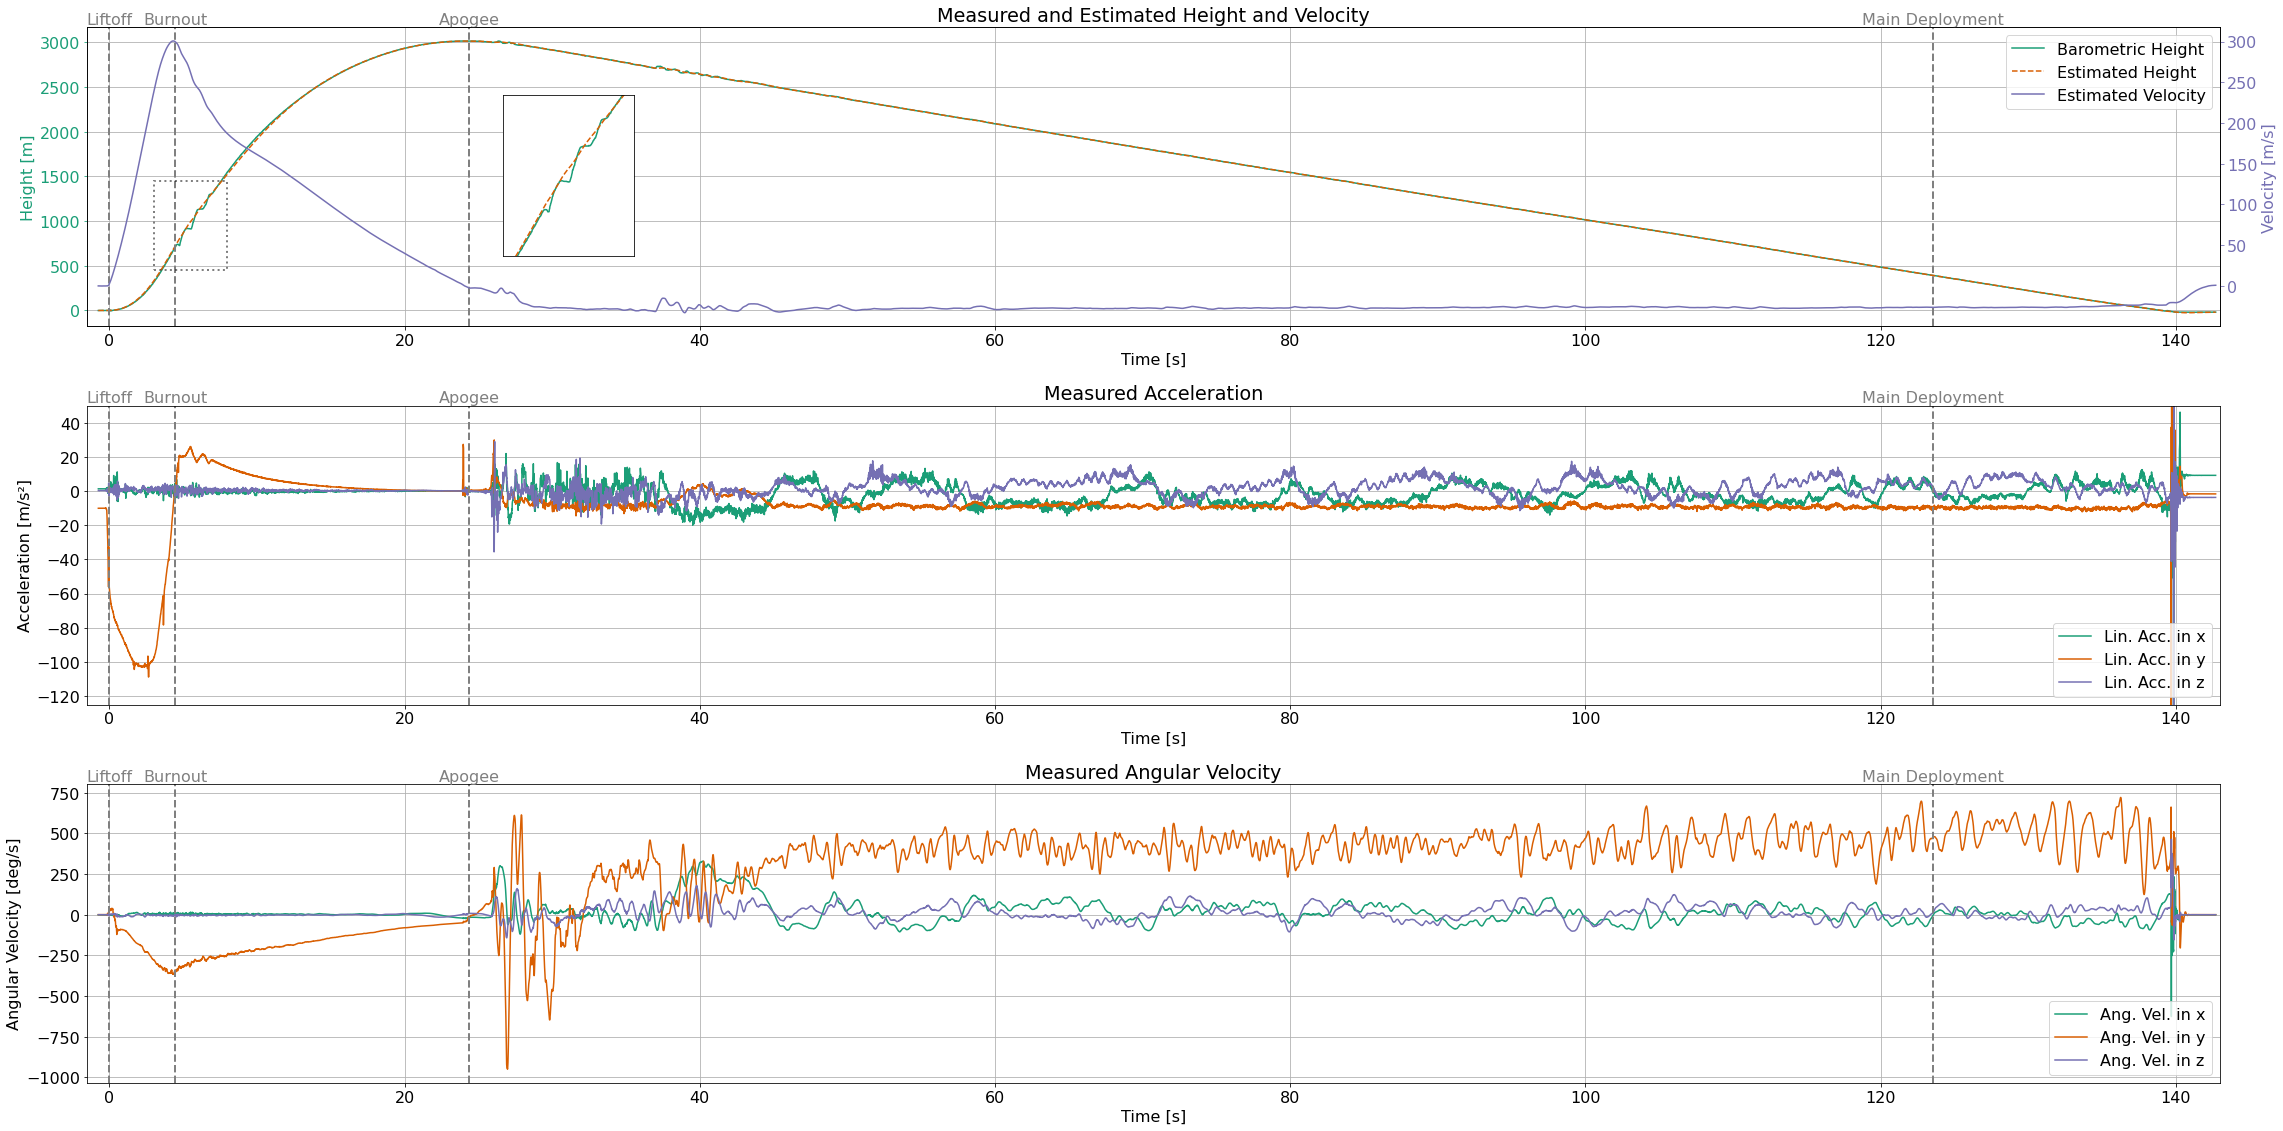

In [147]:
plt.rcParams.update({'font.size': 16})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#1b9e77','#d95f02','#7570b3'])
fig, axs = plt.subplots(3, 1, figsize=(32, 16))
# plt.subplots_adjust(wspace=2.5)

# Height and Velocity
ax_vel = axs[0].twinx()
height_line = axs[0].plot(filtered_data_info_df['ts'], filtered_data_info_df['filtered_altitude_AGL'], label='Barometric Height', color = '#1b9e77')
est_height_line = axs[0].plot(flight_info_df['ts'], flight_info_df['height'], label='Estimated Height', linestyle='--', color='#d95f02')
axs[0].set_title('Measured and Estimated Height and Velocity')
axs[0].set_xlabel('Time [s]')
axs[0].set_ylabel('Height [m]', color='#1b9e77')
axs[0].set_xlim(-1.5, 143)  # Set x-axis limits
axs[0].tick_params(axis='y', colors='#1b9e77')

vel_line = ax_vel.plot(flight_info_df['ts'], flight_info_df['velocity'], label='Estimated Velocity', color='#7570b3')
ax_vel.set_ylabel('Velocity [m/s]', color='#7570b3')
ax_vel.tick_params(axis='y', colors='#7570b3')

# Combine legends for both axes
lines = height_line + est_height_line + vel_line
labels = [line.get_label() for line in lines]
axs[0].legend(lines, labels, loc='upper right')
axs[0].grid(True)


# Add an inset plot for the zoomed-in area
offset_x = 0.26  # Relative to the width of axs[0] (right direction)
offset_y = 0.80  # Relative to the height of axs[0] (up direction)
ax_inset = inset_axes(axs[0], width=2.6*0.7, height=3.2*0.7,  bbox_to_anchor=(offset_x, offset_y, 0, 0), bbox_transform=axs[0].transAxes)
ax_inset.plot(filtered_data_info_df['ts'], filtered_data_info_df['filtered_altitude_AGL'], color='#1b9e77')
ax_inset.plot(flight_info_df['ts'], flight_info_df['height'], linestyle='--', color='#d95f02')
ax_inset.plot(flight_info_df['ts'], flight_info_df['velocity'], color='#7570b3')

# Set the limits for the zoomed-in area
ax_inset.set_xlim(3, 8)
ax_inset.set_ylim(450, 1450)

ax_inset.grid(True)
ax_inset.set_xticks([])
ax_inset.set_yticks([])

# Optionally, add a rectangle on the main plot to show the zoom area
axs[0].indicate_inset_zoom(ax_inset, edgecolor="black", linestyle='dotted', linewidth=2)

# Acceleration
axs[1].plot(imu_df['ts'], imu_df['Ax'] * 20, label='Lin. Acc. in x')
axs[1].plot(imu_df['ts'], imu_df['Ay'] * 20, label='Lin. Acc. in y')
axs[1].plot(imu_df['ts'], imu_df['Az'] * 20, label='Lin. Acc. in z')
axs[1].set_title('Measured Acceleration')
axs[1].set_xlabel('Time [s]')
axs[1].set_ylabel('Acceleration [m/s²]')
axs[1].set_xlim(-1.5, 143)  # Set x-axis limits
axs[1].set_ylim(-125, 50)  # Set x-axis limits
axs[1].legend(loc='lower right')
axs[1].grid(True)

# Angular Velocity
axs[2].plot(imu_df['ts'], imu_df['Gx'], label='Ang. Vel. in x')
axs[2].plot(imu_df['ts'], imu_df['Gy'], label='Ang. Vel. in y')
axs[2].plot(imu_df['ts'], imu_df['Gz'], label='Ang. Vel. in z')
axs[2].set_title('Measured Angular Velocity')
axs[2].set_xlabel('Time [s]')
axs[2].set_ylabel('Angular Velocity [deg/s]')
axs[2].set_xlim(-1.5, 143)  # Set x-axis limits
axs[2].legend(loc='lower right')
axs[2].grid(True)


# Add vertical lines for each event
for index, row in event_info_df.iterrows():
    for ax in axs:
        ax.axvline(x=row['ts'], color='grey', linestyle='--', linewidth=2)
        ax.text(row['ts'], ax.get_ylim()[1], row['event'], verticalalignment='bottom', horizontalalignment='center', color='grey', fontsize=16)

plt.tight_layout()
plt.savefig('plot.png', format='png', dpi=300, facecolor='white')
plt.savefig('plot.svg', format='svg')
plt.show()


In [132]:
fig.get_size_inches()

array([32., 16.])